# checkbox classifier

dataset used: [meghnagera15/checkbox-cropped-binary](https://huggingface.co/datasets/meghnagera15/checkbox-cropped-binary) (1000 train, 300 validation, 400 test crops). Weights are saved to `models/checkbox_cnn.pt`.

The dataset contains document photo scans. I trained it on grayscale as images are always grayscaled with openCV as a preprocessing step on the classification service.

In [5]:
from datasets import load_dataset

ds = load_dataset("meghnagera15/checkbox-cropped-binary")


In [6]:
import os
import sys
from pathlib import Path

# Jupyter starts in notebooks/, run from backend/ instead so imports and paths resolve the way they do for the app and tests.
if Path.cwd().name == "notebooks":
    os.chdir("..")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import copy
import random

import torch
from PIL import Image, ImageDraw
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2

from services.classifier import MODEL_PATH, CheckboxCNN, CheckboxClassifierService, preprocess
from tests.evaluation import ClassificationResult

torch.manual_seed(0)
random.seed(0)

CHECKED = ds["train"].features["label"].str2int("checked")

## Data

In [7]:
def random_lowres(img: Image.Image, p: float = 0.3) -> Image.Image:
    """Sometimes blur detail away the way a low-res page does: shrink, then scale back up."""
    if random.random() < p:
        side = random.randint(16, 48)
        img = img.resize((side, side), Image.BILINEAR).resize(img.size, Image.BILINEAR)
    return img


augment = v2.Compose([
    v2.Grayscale(),
    v2.RandomRotation(5, fill=255),
    v2.RandomResizedCrop(224, scale=(0.7, 1.0), ratio=(0.8, 1.25)),
    v2.ColorJitter(brightness=0.3, contrast=0.3),
    v2.RandomApply([v2.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
    random_lowres,
])


def make_transform(train: bool):
    def transform(batch):
        images = [augment(img) if train else img for img in batch["image"]]
        return {
            "x": [preprocess(img) for img in images],
            "y": [float(label == CHECKED) for label in batch["label"]],
        }
    return transform


train_loader = DataLoader(ds["train"].with_transform(make_transform(train=True)), batch_size=64, shuffle=True)
val_loader = DataLoader(ds["validation"].with_transform(make_transform(train=False)), batch_size=64)
test_loader = DataLoader(ds["test"].with_transform(make_transform(train=False)), batch_size=64)

checked: [1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0]


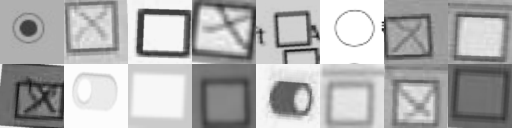

In [8]:
sample = next(iter(train_loader))
grid = Image.new("L", (8 * 64, 2 * 64))
for i, x in enumerate(sample["x"][:16]):
    grid.paste(Image.fromarray(((x[0] + 1) * 127.5).byte().numpy()), ((i % 8) * 64, (i // 8) * 64))
print("checked:", [int(y) for y in sample["y"][:16]])
grid

## Train

In [ ]:
EPOCHS = 30

model = CheckboxCNN()
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")


def run_epoch(loader, optimizer=None) -> tuple[float, float]:
    """One pass over loader; trains when an optimizer is given. Returns (mean loss, accuracy)."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for batch in loader:
            y = batch["y"].float()
            logits = model(batch["x"])
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += ((logits > 0) == (y > 0.5)).sum().item()
            n += len(y)
    return total_loss / n, correct / n


best_acc, best_state = 0.0, None
print(f"{'epoch':>5} {'train loss':>10} {'train acc':>9} {'val loss':>8} {'val acc':>7}")
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, optimizer)
    val_loss, val_acc = run_epoch(val_loader)
    scheduler.step()
    marker = ""
    if val_acc > best_acc:
        best_acc, best_state, marker = val_acc, copy.deepcopy(model.state_dict()), " *"
    print(f"{epoch:5} {train_loss:10.4f} {train_acc:9.3f} {val_loss:8.4f} {val_acc:7.3f}{marker}")

In [ ]:
MODEL_PATH.parent.mkdir(exist_ok=True)
torch.save(best_state, MODEL_PATH)
print(f"saved best model (val acc {best_acc:.3f}) to {MODEL_PATH}")

## Test

The test split is scored once, with the saved weights loaded through the service. That way the file and the loading code get exercised as well. Metrics use the same "checked = positive" convention as the pytest report.

In [11]:
test_model = CheckboxClassifierService(MODEL_PATH).model
with torch.inference_mode():
    logits = torch.cat([test_model(batch["x"]) for batch in test_loader])

result, wrong = ClassificationResult(), []
for example, logit in zip(ds["test"], logits, strict=True):
    predicted, actual = bool(logit > 0), example["label"] == CHECKED
    result.add(predicted, actual)
    if predicted != actual:
        wrong.append((example["image"], actual))
f1 = 2 * result.precision * result.recall / (result.precision + result.recall) if result.precision + result.recall > 0 else 0.0
print(f"n={result.n}  accuracy={result.accuracy:.3f}  precision={result.precision:.3f}  recall={result.recall:.3f} f1={f1:.3f}")
print(f"TP={result.tp}  FP={result.fp}  FN={result.fn}  TN={result.tn}")

n=400  accuracy=0.948  precision=0.984  recall=0.910 f1=0.945
TP=182  FP=3  FN=18  TN=197


In [ ]:
# Misclassified test crops, captioned with their true label.
THUMB, COLS = 96, 8
rows = max(1, -(-len(wrong) // COLS))
grid = Image.new("RGB", (COLS * THUMB, rows * (THUMB + 14)), "white")
draw = ImageDraw.Draw(grid)
for i, (img, actual) in enumerate(wrong):
    x, y = (i % COLS) * THUMB, (i // COLS) * (THUMB + 14)
    grid.paste(img.resize((THUMB, THUMB)), (x, y))
    draw.text((x + 2, y + THUMB), "checked" if actual else "unchecked", fill="black")
print(f"{len(wrong)} misclassified")
grid